# Ejercicio 6. Más capas en Iris



In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
import importlib.util
import json
import platform
import sys
from pathlib import Path
from time import perf_counter

# Si falta algún paquete, lo instalo aquí.
required = {"numpy": "numpy", "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tensorflow": "tensorflow", "pandas": "pandas"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
SEED = 42
EN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
ENTORNO = "Google Colab" if EN_COLAB else "Ejecución local"
print(ENTORNO)
print("Python:", platform.python_version(), "| Sistema:", platform.platform())
print("Semilla:", SEED, "| Épocas: 500 | Tasa: 0.03")

Ejecución local
Python: 3.11.18 | Sistema: macOS-26.6.2-arm64-arm-64bit
Semilla: 42 | Épocas: 500 | Tasa: 0.03


## 1. Primero, la red de clase

Empiezo con la red de 4 x 3 x 3. Le puse una semilla para repetir la prueba,
tomé el tiempo y guardé las gráficas. Cambié `np.random.rand(1)` por
`np.random.rand()` para que funcione con la versión de NumPy que uso.

Este código suma el error de las tres salidas y saca el promedio entre las flores.
Keras también promedia entre las tres salidas. Divido el primero entre 3 para
compararlos con la misma medida: MSE.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from sklearn import datasets

Matplotlib is building the font cache; this may take a moment.


In [3]:
np.random.seed(SEED)

In [4]:
iris = datasets.load_iris()
X = iris.data
target = iris.target
Y = to_categorical(target).astype("uint8")

In [5]:
idx = 0
print(X[idx])
print(target[idx])
print(Y[idx])
idx = 50
print(X[idx])
print(target[idx])
print(Y[idx])
idx = 100
print(X[idx])
print(target[idx])
print(Y[idx])

[5.1 3.5 1.4 0.2]
0
[1 0 0]
[7.  3.2 4.7 1.4]
1
[0 1 0]
[6.3 3.3 6.  2.5]
2
[0 0 1]


In [6]:
# La red empieza con 4 entradas, 3 neuronas ocultas y 3 de salida.
input_size_layer1 = 4
num_neurons_layer1 = 3

input_size_layer2 = num_neurons_layer1
num_neurons_layer2 = 3

layer1 = list()
layer2 = list()

In [7]:
def generate_weights(num_weights):
  w = np.zeros(num_weights)
  for i in range(len(w)):
    w[i] = (np.random.rand() - 0.5)
  return w

def init_weights():
  layer1.clear()
  layer2.clear()
  for i in range(num_neurons_layer1):
    layer1.append( generate_weights(input_size_layer1+1)) # El peso extra es para el sesgo.
  for i in range(num_neurons_layer2):
    layer2.append( generate_weights(input_size_layer2+1)) # El peso extra es para el sesgo.

def net_input(input_vector, w):
  net_input_var = w[0]
  for i in range(len(input_vector)):
    net_input_var += w[i+1] * input_vector[i]
  return net_input_var

def sigmoid(z):
  activation = 1/(1+np.power(np.e, -z))
  return activation

def propagate(X, w):
  neuronInput = net_input(X, w) # Sumo las entradas con sus pesos.
  neuronOutput = sigmoid(neuronInput) # Paso la suma por la sigmoide.
  return neuronOutput

def calculate_error():
  total_err = 0
  for idx in range(len(X)):
    output_layer1 = np.zeros(num_neurons_layer1)
    for i in range(len(output_layer1)):
      output_layer1[i] = propagate(X[idx], layer1[i])

    output_layer2 = np.zeros(num_neurons_layer2)
    for i in range(len(output_layer2)):
      output_layer2[i] = propagate(output_layer1, layer2[i])

    err = Y[idx] - output_layer2
    err = np.power(err,2)
    err = err.sum()
    total_err += err

  return total_err / ( len(X) )

In [8]:
print(generate_weights(5))

[-0.12545988  0.45071431  0.23199394  0.09865848 -0.34398136]


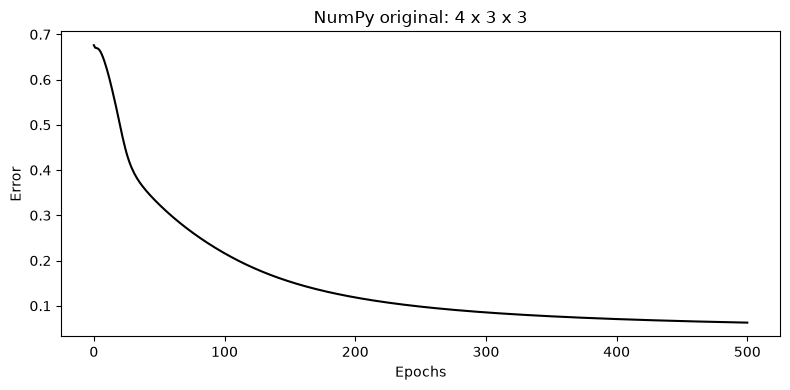

In [9]:
np.random.seed(SEED)
inicio_original = perf_counter()
alpha = 0.03
epochs = 500

init_weights()

E = list()
E.append( calculate_error() )
for e in range(epochs):
  for d in range(len(X)):
    # Paso los datos por la red.
    output_layer1 = np.zeros(num_neurons_layer1)
    for i in range(len(output_layer1)):
      output_layer1[i] = propagate(X[d], layer1[i])

    output_layer2 = np.zeros(num_neurons_layer2)
    for i in range(len(output_layer2)):
      output_layer2[i] = propagate(output_layer1, layer2[i])

    # Calculo los errores para ajustar los pesos.
    delta_layer2 = np.zeros(num_neurons_layer2)
    for i in range(len(delta_layer2)):
      delta_layer2[i] = output_layer2[i] * (1 - output_layer2[i]) * (Y[d][i] - output_layer2[i])

    for i in range(len(layer2)):
      layer2[i][0] += alpha * delta_layer2[i] * 1
      for j in range(len(layer2[i])-1):
        layer2[i][j+1] += alpha * delta_layer2[i] * output_layer1[j]

    delta_layer1 = np.zeros(num_neurons_layer1)
    for i in range(len(delta_layer1)):
      weighted_delta_errors = 0
      for j in range(num_neurons_layer2):
        weighted_delta_errors += layer2[i][j+1] * delta_layer2[j]
      delta_layer1[i] = output_layer1[i] * (1 - output_layer1[i]) * weighted_delta_errors

    for i in range(len(layer1)):
      layer1[i][0] += alpha * delta_layer1[i] * 1
      for j in range(len(layer1[i])-1):
        layer1[i][j+1] += alpha * delta_layer1[i] * X[d][j]

  E.append( calculate_error() )

tiempo_original = perf_counter() - inicio_original
Error_vec = np.asarray(E)
plt.figure(figsize=(8, 4))
plt.plot(Error_vec, color='black')
plt.title('NumPy original: 4 x 3 x 3')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.tight_layout()
plt.savefig(RESULTADOS / 'numpy_original_curva.png', dpi=160)
plt.show()

In [10]:
def predict_original(datos):
    outputs = []
    for sample in datos:
        hidden = np.array([propagate(sample, weights) for weights in layer1])
        outputs.append([propagate(hidden, weights) for weights in layer2])
    return np.asarray(outputs)

pred_original = predict_original(X)
metricas_original = {
    "topologia": [4, 3, 3],
    "error_sse_por_muestra_final": float(E[-1]),
    "mse_final": float(np.mean((Y - pred_original) ** 2)),
    "precision_entrenamiento": float(np.mean(pred_original.argmax(axis=1) == target)),
    "segundos": tiempo_original,
}
print("CORRIDA ORIGINAL NUMPY")
for key, value in metricas_original.items():
    print(key, ":", value)
print("Cada 50 épocas (SSE / número de flores):")
for epoch in range(0, epochs + 1, 50):
    print(f"Época {epoch:3d}: {E[epoch]:.6f}")
print("Ejemplo [3,3,1,1]:", predict_original(np.array([[3, 3, 1, 1]]))[0])

CORRIDA ORIGINAL NUMPY
topologia : [4, 3, 3]
error_sse_por_muestra_final : 0.06279104537701374
mse_final : 0.02093034845900458
precision_entrenamiento : 0.96
segundos : 2.012227041999722
Cada 50 épocas (SSE / número de flores):
Época   0: 0.676060
Época  50: 0.323900
Época 100: 0.216104
Época 150: 0.153318
Época 200: 0.118474
Época 250: 0.098168
Época 300: 0.085369
Época 350: 0.076756
Época 400: 0.070663
Época 450: 0.066183
Época 500: 0.062791
Ejemplo [3,3,1,1]: [9.69585149e-01 4.72829259e-02 8.08379806e-04]


## 2. Ahora le pongo dos capas más





CORRIDA PROFUNDA NUMPY: 4 x 3 x 3 x 3 x 3


Época  50: 0.670597


Época 100: 0.670392


Época 150: 0.670225


Época 200: 0.670054


Época 250: 0.669827


Época 300: 0.669417


Época 350: 0.668285


Época 400: 0.662153


Época 450: 0.540626


Época 500: 0.406424
topologia : [4, 3, 3, 3, 3]
error_sse_por_muestra_final : 0.406423832817962
mse_final : 0.13547461093932067
precision_entrenamiento : 0.7066666666666667
segundos : 2.9070119999996678
Ejemplo [3,3,1,1]: [0.62814511 0.42621388 0.0442126 ]


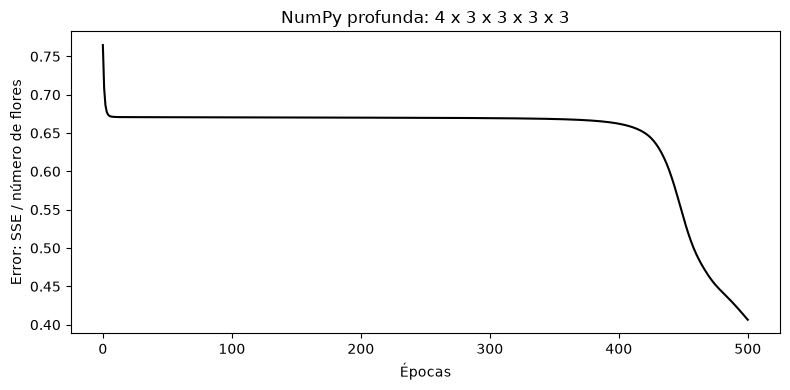

In [11]:
# Ahora uso 4 entradas, 3 capas ocultas de 3 y 3 salidas.
# Guardo el sesgo en la primera columna de cada matriz.
tamanos = [4, 3, 3, 3, 3]

def init_weights_deep(tamanos, seed=SEED):
    rng = np.random.RandomState(seed)
    return [rng.rand(salida, entrada + 1) - 0.5
            for entrada, salida in zip(tamanos[:-1], tamanos[1:])]

def forward_deep(sample, pesos):
    activaciones = [np.asarray(sample, dtype=float)]
    for weights in pesos:
        activaciones.append(sigmoid(weights[:, 0] + weights[:, 1:] @ activaciones[-1]))
    return activaciones

def calculate_error_deep(pesos):
    pred = np.array([forward_deep(sample, pesos)[-1] for sample in X])
    return float(np.mean(np.sum((Y - pred) ** 2, axis=1)))

def train_deep(tamanos, alpha=0.03, epochs=500):
    pesos = init_weights_deep(tamanos)
    errores = [calculate_error_deep(pesos)]
    inicio = perf_counter()
    for epoch in range(epochs):
        for sample, expected in zip(X, Y):
            activaciones = forward_deep(sample, pesos)
            deltas = [None] * len(pesos)
            salida = activaciones[-1]
            deltas[-1] = salida * (1 - salida) * (expected - salida)
            # Primero saco todos los deltas y después cambio los pesos.
            for layer in range(len(pesos) - 2, -1, -1):
                activation = activaciones[layer + 1]
                error_atras = pesos[layer + 1][:, 1:].T @ deltas[layer + 1]
                deltas[layer] = activation * (1 - activation) * error_atras
            for layer in range(len(pesos)):
                entrada_con_bias = np.r_[1.0, activaciones[layer]]
                pesos[layer] += alpha * np.outer(deltas[layer], entrada_con_bias)
        errores.append(calculate_error_deep(pesos))
        if (epoch + 1) % 50 == 0:
            print(f"Época {epoch + 1:3d}: {errores[-1]:.6f}")
    return pesos, errores, perf_counter() - inicio

print("CORRIDA PROFUNDA NUMPY: 4 x 3 x 3 x 3 x 3")
pesos_profundos, E_profunda, tiempo_profundo = train_deep(tamanos)
layer1_profunda, layer2_profunda, layer3_profunda, layer4_profunda = pesos_profundos
assert [w.shape for w in pesos_profundos] == [(3, 5), (3, 4), (3, 4), (3, 4)]
pred_profunda = np.array([forward_deep(sample, pesos_profundos)[-1] for sample in X])
metricas_profunda = {
    "topologia": tamanos,
    "error_sse_por_muestra_final": float(E_profunda[-1]),
    "mse_final": float(np.mean((Y - pred_profunda) ** 2)),
    "precision_entrenamiento": float(np.mean(pred_profunda.argmax(axis=1) == target)),
    "segundos": tiempo_profundo,
}
for key, value in metricas_profunda.items():
    print(key, ":", value)
print("Ejemplo [3,3,1,1]:", forward_deep(np.array([3, 3, 1, 1]), pesos_profundos)[-1])
plt.figure(figsize=(8, 4))
plt.plot(E_profunda, color="black")
plt.xlabel("Épocas")
plt.ylabel("Error: SSE / número de flores")
plt.title("NumPy profunda: 4 x 3 x 3 x 3 x 3")
plt.tight_layout()
plt.savefig(RESULTADOS / "numpy_profunda_curva.png", dpi=160)
plt.show()

## 3. Comparo las dos redes


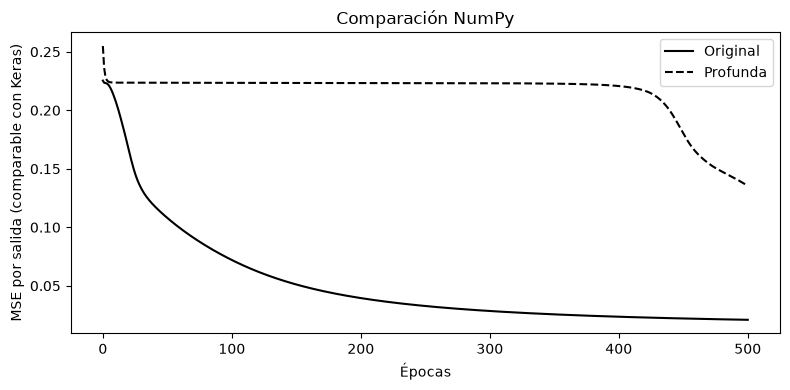

MSE original: 0.02093034845900458
MSE profunda: 0.13547461093932067
Cambio de MSE (profunda - original): 0.1145442624803161
Con cuatro sigmoides, los gradientes pueden hacerse pequeños; más capas no garantizan menor error.


In [12]:
plt.figure(figsize=(8, 4))
plt.plot(np.array(E) / 3, color="black", label="Original")
plt.plot(np.array(E_profunda) / 3, color="black", linestyle="--", label="Profunda")
plt.xlabel("Épocas")
plt.ylabel("MSE por salida (comparable con Keras)")
plt.title("Comparación NumPy")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "numpy_comparacion.png", dpi=160)
plt.show()
metricas_numpy = {"entorno": ENTORNO, "semilla": SEED, "epocas": 500, "tasa": 0.03,
                  "original": metricas_original, "profunda": metricas_profunda}
(RESULTADOS / "numpy_metricas.json").write_text(json.dumps(metricas_numpy, ensure_ascii=False, indent=2))
print("MSE original:", metricas_original["mse_final"])
print("MSE profunda:", metricas_profunda["mse_final"])
print("Cambio de MSE (profunda - original):", metricas_profunda["mse_final"] - metricas_original["mse_final"])
print("Con cuatro sigmoides, los gradientes pueden hacerse pequeños; más capas no garantizan menor error.")

Las dos redes usan 4 entradas, 3 salidas, sigmoides, 500 épocas y aprendizaje
de 0.03. Las flores son las mismas y no las normalicé.

Al final del cuaderno de Keras comparo las cuatro pruebas.
Las capturas están en capturas.docx.
